# EDA theo thời gian — Huy

Đồ án đề tài 15, nhóm 4 người — Trường Đại học Sài Gòn, GV Đỗ Như Tài.

**Mục tiêu:** mô tả doanh thu, số hóa đơn, số khách theo tháng/tuần, theo giờ trong ngày và thứ trong tuần; tìm mùa vụ và điểm bất thường (tuần cuối năm, tháng cuối dữ liệu chưa đủ); đánh dấu `CUTOFF = 2011-09-09` và kiểm tra hai giai đoạn quan sát/kiểm chứng có tương đương nhau không. Đây là EDA mô tả, chưa huấn luyện hay chọn mô hình.

**Ranh giới thời gian và data leakage:** để so sánh hai giai đoạn, notebook này phải nhìn cả hai phía của cutoff, nhưng **chỉ để mô tả**. Không có scaler, ngưỡng, đặc trưng hay tham số nào được ước lượng từ giai đoạn kiểm chứng, và các con số ở đây không được dùng để chọn mô hình hay tham số (giai đoạn kiểm chứng vẫn chỉ dành cho đánh giá ngoài RQ3). Bộ lọc bên dưới chỉ gồm quy tắc logic (dấu hóa đơn, dấu số lượng, giá), không có ngưỡng thống kê tính từ dữ liệu.

Nguồn: [UCI Online Retail — Chen (2015)](https://archive.ics.uci.edu/dataset/352/online+retail). Đơn giá tính bằng GBP; hóa đơn bắt đầu bằng `C` là hóa đơn hủy. Mọi số liệu trong notebook được tính trực tiếp từ file.

In [1]:
from pathlib import Path
import sys

# Hỗ trợ chạy từ thư mục gốc hoặc notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import shutil
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.config import SEED, CUTOFF, DATA_RAW, TABLES_DIR, FIGURES_DIR
from src.data_loader import load_raw
from src import eda_time as et

np.random.seed(SEED)  # notebook này không có bước ngẫu nhiên; đặt seed cho thống nhất
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.1f}'.format)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Repo lưu file gốc tên "Online Retail.xlsx" (có dấu cách), còn config/load_raw đọc "Online_Retail.xlsx".
# Tạo bản sao cục bộ khi thiếu; data/raw/* nằm trong .gitignore nên bản sao này không bị commit.
alt_name = DATA_RAW.with_name('Online Retail.xlsx')
if not DATA_RAW.exists() and alt_name.exists():
    shutil.copy(alt_name, DATA_RAW)

versions = {p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'matplotlib', 'openpyxl']}
display({'SEED': SEED, 'CUTOFF': CUTOFF, 'Python': platform.python_version(), 'versions': versions})

{'SEED': 42,
 'CUTOFF': '2011-09-09',
 'Python': '3.13.17',
 'versions': {'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5'}}

## 1. Kiểm kê dữ liệu và bộ lọc nhẹ

Đơn vị mỗi dòng là một mặt hàng trong hóa đơn, nên **số dòng không phải số giao dịch**; notebook đếm riêng dòng, hóa đơn (`InvoiceNo` khác nhau) và khách (`CustomerID` khác nhau). Dùng `load_raw(use_cache=False)` để Restart & Run All đọc lại Excel, không dính cache cũ.

Doanh thu = `Quantity × UnitPrice`. Để đo hoạt động bán hàng theo thời gian, notebook dùng bộ lọc nhẹ riêng (không chờ `clean_transactions`), mỗi bước có lý do:

- **Bỏ hóa đơn hủy (`InvoiceNo` bắt đầu bằng `C`):** đây là dòng âm, không phải lượt bán; cộng vào sẽ làm doanh thu và số hóa đơn sai ý nghĩa. Giá trị hủy vẫn được tính riêng ở mục 2 để thấy mức ảnh hưởng.
- **Giữ `Quantity > 0` và `UnitPrice > 0`:** dòng số lượng âm không có chữ `C` là điều chỉnh/trả hàng, dòng giá 0 là hàng miễn phí hoặc giá lỗi; cả hai không phải doanh thu bán thật.
- **Không bỏ dòng thiếu `CustomerID`:** đó vẫn là doanh thu và hóa đơn thật; chỉ khi đếm khách thì tự bỏ qua giá trị thiếu. Mục 2 báo tỷ trọng doanh thu thiếu ID theo tháng để biết mức ảnh hưởng lên số khách.
- **Không xóa dòng trùng, không cắt ngoại lệ, không bỏ mã phí (`POST`, `M`, ...):** chưa có căn cứ coi là lỗi, và ngoại lệ lớn chính là điểm bất thường cần quan sát ở mục 5. Quyết định làm sạch cho RFM thuộc bước riêng của nhóm.

In [2]:
raw = load_raw(use_cache=False)
expected = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
assert raw.columns.tolist() == expected and len(raw) == 541_909
assert raw.InvoiceDate.notna().all()

sales, filter_log = et.light_sales(raw)
cut = pd.Timestamp(CUTOFF)
assert (sales.GiaiDoan == et.OBS).sum() + (sales.GiaiDoan == et.VAL).sum() == len(sales)
assert sales.loc[sales.GiaiDoan == et.OBS, 'InvoiceDate'].max() < cut
assert sales.loc[sales.GiaiDoan == et.VAL, 'InvoiceDate'].min() >= cut
assert filter_log.removed_rows.sum() == len(raw) - len(sales)

display(filter_log)
inventory = {
    'rows_raw': len(raw), 'rows_sales': len(sales),
    'date_min': str(raw.InvoiceDate.min()), 'date_max': str(raw.InvoiceDate.max()),
    'sales_rows_missing_customer_pct': round(float(sales.CustomerID.isna().mean() * 100), 2),
    'sales_duplicate_rows_kept': int(sales[raw.columns].duplicated().sum()),
    'weekdays_with_sales': sorted(sales.Date.dt.dayofweek.unique().tolist()),
}
assert inventory['weekdays_with_sales'] == [0, 1, 2, 3, 4, 6]  # thứ 7 (=5) không có hóa đơn nào
display(inventory)
filter_log.to_csv(TABLES_DIR / 'eda_time_filter_log.csv', index=False, encoding='utf-8-sig')
display(Markdown(
    f"Sau bộ lọc còn {len(sales):,} / {len(raw):,} dòng ({len(sales) / len(raw) * 100:.1f}%). "
    f"{inventory['sales_rows_missing_customer_pct']}% dòng bán thiếu `CustomerID` được giữ lại, "
    f"và {inventory['sales_duplicate_rows_kept']:,} dòng trùng hoàn toàn cũng chưa bị xóa. "
    "Trong toàn bộ dữ liệu không có hóa đơn nào vào **thứ Bảy** (chỉ có các thứ 2–6 và Chủ nhật); "
    "vì vậy thứ Bảy không bị coi là ngày nghỉ bất thường ở các phần dưới."
))

,step,remaining_rows,removed_rows
0,Toàn file,541909,0
1,Bỏ hóa đơn hủy (InvoiceNo bắt đầu C),532621,9288
2,Giữ Quantity > 0 (bỏ trả hàng/điều chỉnh),531285,1336
3,Giữ UnitPrice > 0 (bỏ hàng miễn phí/giá lỗi),530104,1181


{'rows_raw': 541909,
 'rows_sales': 530104,
 'date_min': '2010-12-01 08:26:00',
 'date_max': '2011-12-09 12:50:00',
 'sales_rows_missing_customer_pct': 24.94,
 'sales_duplicate_rows_kept': 5226,
 'weekdays_with_sales': [0, 1, 2, 3, 4, 6]}

Sau bộ lọc còn 530,104 / 541,909 dòng (97.8%). 24.94% dòng bán thiếu `CustomerID` được giữ lại, và 5,226 dòng trùng hoàn toàn cũng chưa bị xóa. Trong toàn bộ dữ liệu không có hóa đơn nào vào **thứ Bảy** (chỉ có các thứ 2–6 và Chủ nhật); vì vậy thứ Bảy không bị coi là ngày nghỉ bất thường ở các phần dưới.

## 2. Theo tháng

Tháng đầu và cuối của dữ liệu không đủ ngày: 12/2010 bắt đầu đúng 01/12/2010 nhưng ngừng giao dịch từ 24/12, còn 12/2011 chỉ có dữ liệu đến 09/12. Vì vậy ngoài tổng tháng, bảng và hình còn có **doanh thu mỗi ngày có giao dịch** để so các tháng có số ngày khác nhau. Cột `cancel_value` là tổng giá trị tuyệt đối trên hóa đơn hủy (gồm cả mã phí/thủ công), chỉ để thấy mức hủy, không trừ vào doanh thu.

,period,phase,trading_days,revenue,invoices,customers,rev_per_trading_day,rev_no_customer_pct,cancel_value
0,2010-12,Quan sát,20,"823,746.1",1559,885,"41,187.3",30.5,"74,789.1"
1,2011-01,Quan sát,24,"691,364.6",1086,741,"28,806.9",17.6,"131,364.3"
2,2011-02,Quan sát,24,"523,631.9",1100,758,"21,818.0",14.6,"25,569.2"
3,2011-03,Quan sát,27,"717,639.4",1454,974,"26,579.2",17.0,"34,372.3"
4,2011-04,Quan sát,21,"537,808.6",1246,856,"25,609.9",12.8,"44,601.5"
5,2011-05,Quan sát,25,"770,536.0",1681,1056,"30,821.4",11.9,"47,202.5"
6,2011-06,Quan sát,26,"761,739.9",1533,991,"29,297.7",13.2,"70,616.8"
7,2011-07,Quan sát,26,"719,221.2",1475,949,"27,662.4",16.6,"37,921.1"
8,2011-08,Quan sát,26,"759,138.4",1361,935,"29,197.6",15.0,"54,333.8"
9,2011-09,Chứa cutoff,26,"1,058,590.2",1837,1266,"40,715.0",10.0,"38,902.6"


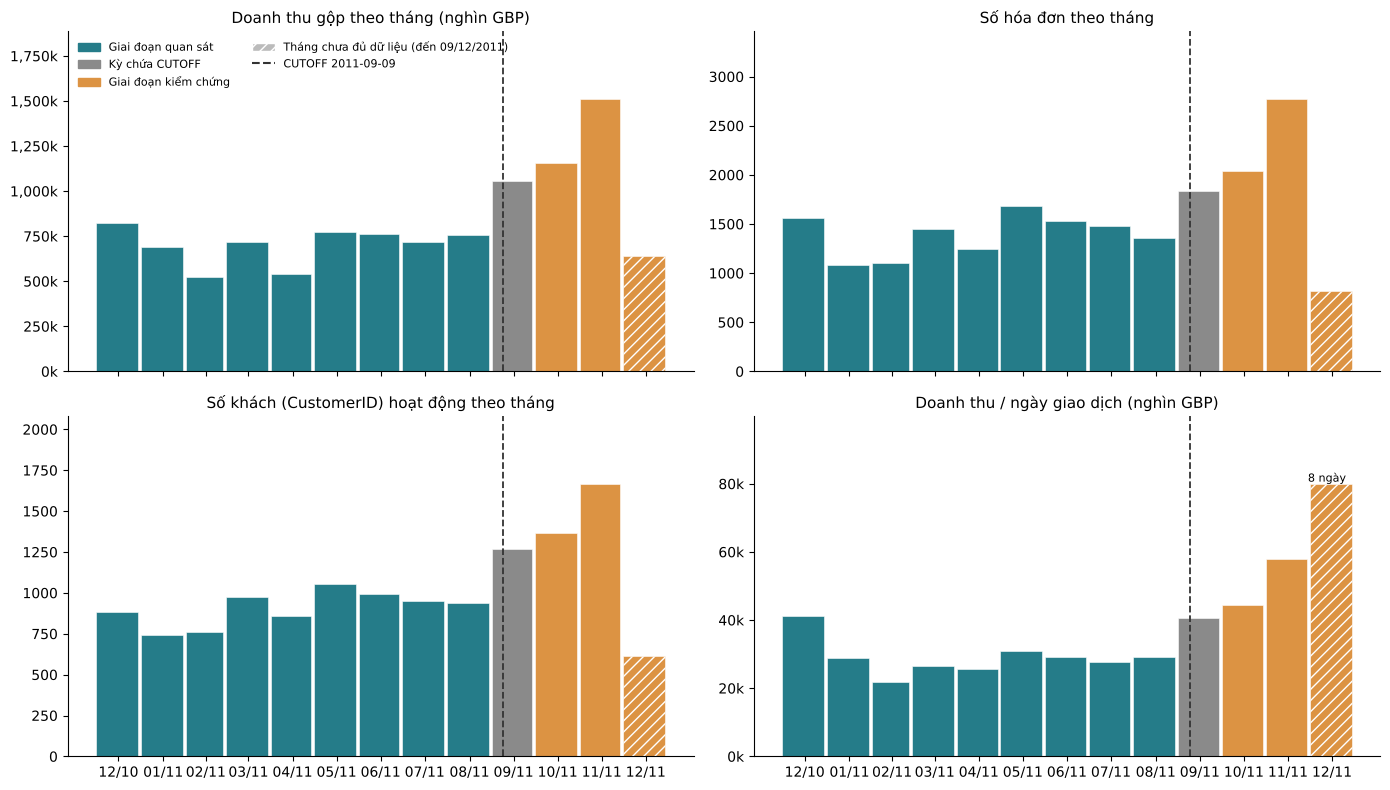

**Nhận xét biểu đồ:** Từ 03/2011 đến 08/2011 doanh thu gộp đi ngang quanh £739,180/tháng (£537,809–£770,536), rồi tăng liên tục từ 09/2011 và đạt đỉnh ở 11/2011 với £1,509,496, gấp 2.0 lần trung vị 03–08, cùng 2,769 hóa đơn và 1,664 khách. 12/2011 trông như sụt giảm (£638,793, 819 hóa đơn) chỉ vì mới có 8 ngày giao dịch; tính theo ngày thì £79,849/ngày, cao nhất toàn dữ liệu. 12/2010 cũng cao (£41,187/ngày) rồi tụt về £21,818/ngày vào 02/2011, nên dữ liệu có mùa vụ cuối năm rõ rệt; chỉ có một năm nên không tách được mùa vụ khỏi xu hướng.

*Ghi chú:* số khách mỗi tháng chỉ đếm `CustomerID` không thiếu. Doanh thu thuộc dòng thiếu ID là 30.5% ở 12/2010 và 17.6% ở 01/2011, so với 11.9–17.0% ở 03–08/2011, nên số khách đầu kỳ bị đếm thấp hơn so với các tháng sau.

In [3]:
monthly = et.aggregate_time(sales, 'M')
cancel_month = et.cancel_value_by_month(raw)
monthly['cancel_value'] = cancel_month.reindex(pd.PeriodIndex(monthly.period, freq='M')).to_numpy()
assert monthly.partial.sum() == 1 and bool(monthly.partial.iloc[-1])  # chỉ 12/2011 là tháng chưa đủ dữ liệu
assert monthly.loc[monthly.revenue.idxmax(), 'period'] == '2011-11'
assert monthly.loc[monthly.rev_per_trading_day.idxmax(), 'period'] == '2011-12'

show_cols = ['period', 'phase', 'trading_days', 'revenue', 'invoices', 'customers',
             'rev_per_trading_day', 'rev_no_customer_pct', 'cancel_value']
display(monthly[show_cols])
monthly.drop(columns=['start', 'end']).to_csv(TABLES_DIR / 'eda_time_monthly.csv', index=False, encoding='utf-8-sig')

et.plot_monthly(monthly)

m = monthly.set_index('period')
base = monthly[(monthly.start >= '2011-03-01') & (monthly.end < '2011-09-01')]
nov, dec11, dec10 = m.loc['2011-11'], m.loc['2011-12'], m.loc['2010-12']
display(Markdown(
    f"**Nhận xét biểu đồ:** Từ 03/2011 đến 08/2011 doanh thu gộp đi ngang quanh £{base.revenue.median():,.0f}/tháng "
    f"(£{base.revenue.min():,.0f}–£{base.revenue.max():,.0f}), rồi tăng liên tục từ 09/2011 và đạt đỉnh ở 11/2011 với "
    f"£{nov.revenue:,.0f}, gấp {nov.revenue / base.revenue.median():.1f} lần trung vị 03–08, cùng {nov.invoices:,} hóa đơn và {nov.customers:,} khách. "
    f"12/2011 trông như sụt giảm (£{dec11.revenue:,.0f}, {dec11.invoices} hóa đơn) chỉ vì mới có {dec11.trading_days} ngày giao dịch; "
    f"tính theo ngày thì £{dec11.rev_per_trading_day:,.0f}/ngày, cao nhất toàn dữ liệu. "
    f"12/2010 cũng cao (£{dec10.rev_per_trading_day:,.0f}/ngày) rồi tụt về £{m.loc['2011-02'].rev_per_trading_day:,.0f}/ngày vào 02/2011, "
    "nên dữ liệu có mùa vụ cuối năm rõ rệt; chỉ có một năm nên không tách được mùa vụ khỏi xu hướng."
))
display(Markdown(
    f"*Ghi chú:* số khách mỗi tháng chỉ đếm `CustomerID` không thiếu. Doanh thu thuộc dòng thiếu ID là {dec10.rev_no_customer_pct:.1f}% ở 12/2010 "
    f"và {m.loc['2011-01'].rev_no_customer_pct:.1f}% ở 01/2011, so với {base.rev_no_customer_pct.min():.1f}–{base.rev_no_customer_pct.max():.1f}% ở 03–08/2011, "
    "nên số khách đầu kỳ bị đếm thấp hơn so với các tháng sau."
))

## 3. Theo tuần

Tuần tính từ thứ 2 đến Chủ nhật. Tuần đầu (29/11–05/12/2010) và tuần cuối (05–11/12/2011) không đủ ngày nên được gạch chéo. Vùng xám là các khoảng liên tiếp từ 2 ngày giao dịch kỳ vọng trở lên mà không có hóa đơn nào (không tính thứ Bảy).

,start,end,trading_days_missing,calendar_days
0,2010-12-24,2011-01-03,9,11
1,2011-04-22,2011-04-25,3,4


{'ngay_don_le_khong_co_giao_dich': ['29/04/2011', '02/05/2011', '30/05/2011', '29/08/2011']}

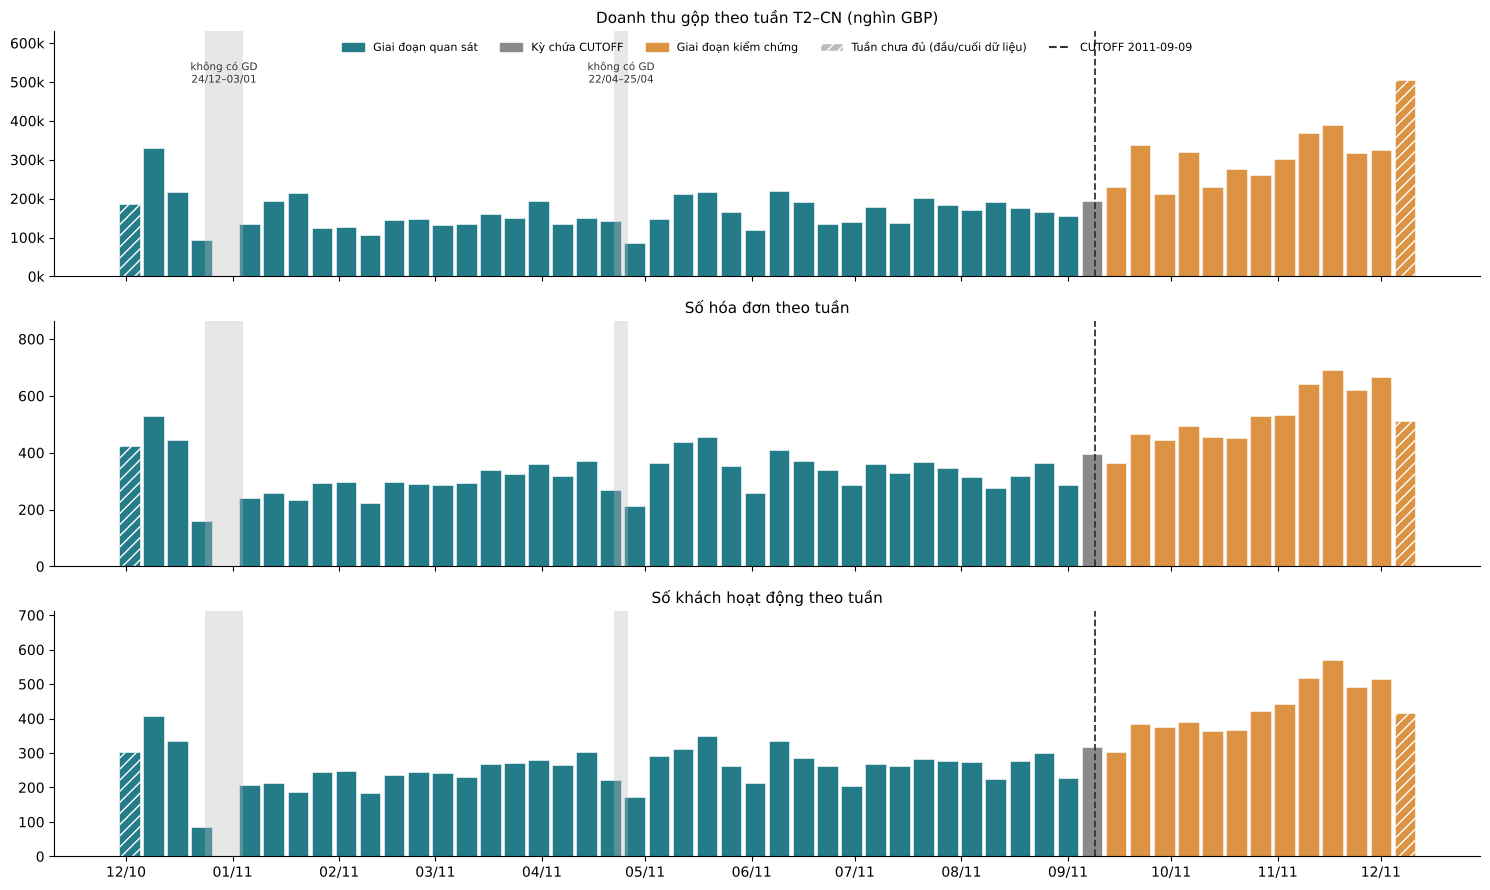

**Nhận xét biểu đồ:** Trung vị doanh thu của các tuần đủ ngày là £151,857 ở giai đoạn quan sát và £309,155 ở giai đoạn kiểm chứng, gấp 2.0 lần, nên chênh lệch giữa hai giai đoạn không chỉ do tuần cuối. Từ 24/12/2010 đến 03/01/2011 không có hóa đơn nào (9 ngày giao dịch kỳ vọng) khiến tuần 20–26/12/2010 chỉ còn £92,369; ngoài ra còn khoảng 22/04–25/04/2011 và 4 ngày lẻ (29/04, 02/05, 30/05, 29/08) trùng lịch nghỉ lễ ở Anh, nhưng đây chỉ là suy đoán vì dữ liệu không ghi lý do. Tuần cuối (05/12–11/12/2011) đạt £504,310, cao nhất toàn dữ liệu, song chỉ có 5 ngày giao dịch và chứa một hóa đơn lớn bị hủy ngay (mục 5) nên không phải bằng chứng của xu hướng tăng.

In [4]:
weekly = et.aggregate_time(sales, 'W')
gaps = et.no_trading_runs(sales, min_days=2)
all_runs = et.no_trading_runs(sales, min_days=1)
single_days = all_runs[all_runs.trading_days_missing == 1].start.dt.strftime('%d/%m/%Y').tolist()
assert weekly.partial.sum() == 2 and bool(weekly.partial.iloc[0]) and bool(weekly.partial.iloc[-1])
display(gaps)
display({'ngay_don_le_khong_co_giao_dich': single_days})
weekly.drop(columns=['start', 'end']).to_csv(TABLES_DIR / 'eda_time_weekly.csv', index=False, encoding='utf-8-sig')
gaps.to_csv(TABLES_DIR / 'eda_time_gaps.csv', index=False, encoding='utf-8-sig')

et.plot_weekly(weekly, gaps)

w = weekly.set_index('period')
full = weekly[~weekly.partial]
med_obs = full.loc[full.phase == et.OBS, 'revenue'].median()
med_val = full.loc[full.phase == et.VAL, 'revenue'].median()
last = weekly.iloc[-1]
year_end = w.loc['2010-12-20/2010-12-26']
assert last.revenue == weekly.revenue.max()
short_days = ', '.join(d[:5] for d in single_days)
display(Markdown(
    f"**Nhận xét biểu đồ:** Trung vị doanh thu của các tuần đủ ngày là £{med_obs:,.0f} ở giai đoạn quan sát và £{med_val:,.0f} ở giai đoạn kiểm chứng, "
    f"gấp {med_val / med_obs:.1f} lần, nên chênh lệch giữa hai giai đoạn không chỉ do tuần cuối. "
    f"Từ {gaps.start[0]:%d/%m/%Y} đến {gaps.end[0]:%d/%m/%Y} không có hóa đơn nào ({gaps.trading_days_missing[0]} ngày giao dịch kỳ vọng) khiến tuần 20–26/12/2010 chỉ còn £{year_end.revenue:,.0f}; "
    f"ngoài ra còn khoảng {gaps.start[1]:%d/%m}–{gaps.end[1]:%d/%m/%Y} và {len(single_days)} ngày lẻ ({short_days}) trùng lịch nghỉ lễ ở Anh, nhưng đây chỉ là suy đoán vì dữ liệu không ghi lý do. "
    f"Tuần cuối ({last.start:%d/%m}–{last.end:%d/%m/%Y}) đạt £{last.revenue:,.0f}, cao nhất toàn dữ liệu, song chỉ có {last.trading_days} ngày giao dịch và chứa một hóa đơn lớn bị hủy ngay (mục 5) "
    "nên không phải bằng chứng của xu hướng tăng."
))

## 4. Theo giờ trong ngày và thứ trong tuần

Đếm theo **hóa đơn** (lấy thời điểm sớm nhất của hóa đơn) thay vì theo dòng, để hóa đơn nhiều mặt hàng không được đếm nhiều lần. Dữ liệu không ghi múi giờ nên giờ là giờ ghi trong file. Mỗi thứ được chia cho số ngày giao dịch của thứ đó, vì số tuần của từng thứ trong khoảng dữ liệu không bằng nhau. Biểu đồ tỷ trọng theo giờ vẽ riêng hai giai đoạn để kiểm tra nhịp trong ngày có thay đổi qua cutoff không.

,invoices,revenue,revenue_pct,revenue_pct_obs,revenue_pct_val
hour,,,,,
6,1,4.2,0.0,0.0,0.0
7,29,"31,059.2",0.3,0.2,0.4
8,566,"283,868.5",2.7,2.8,2.5
9,1484,"990,267.8",9.3,8.2,11.0
10,2361,"1,446,742.7",13.6,14.0,12.8
11,2396,"1,239,981.8",11.6,11.7,11.5
12,3219,"1,444,218.5",13.5,13.3,13.9
13,2753,"1,265,736.3",11.9,12.3,11.1
14,2457,"1,181,812.4",11.1,11.3,10.7


,label,trading_days,invoices,revenue,invoices_per_day,revenue_per_day,revenue_pct
0,T2,47,3126,"1,779,575.0",66.5,"37,863.3",16.7
1,T3,52,3554,"2,178,632.6",68.3,"41,896.8",20.4
2,T4,53,3690,"1,851,147.8",69.6,"34,927.3",17.4
3,T5,53,4246,"2,203,161.2",80.1,"41,569.1",20.7
4,T6,50,3140,"1,840,340.2",62.8,"36,806.8",17.3
5,T7,0,0,0.0,0.0,0.0,0.0
6,CN,50,2204,"813,827.6",44.1,"16,276.6",7.6


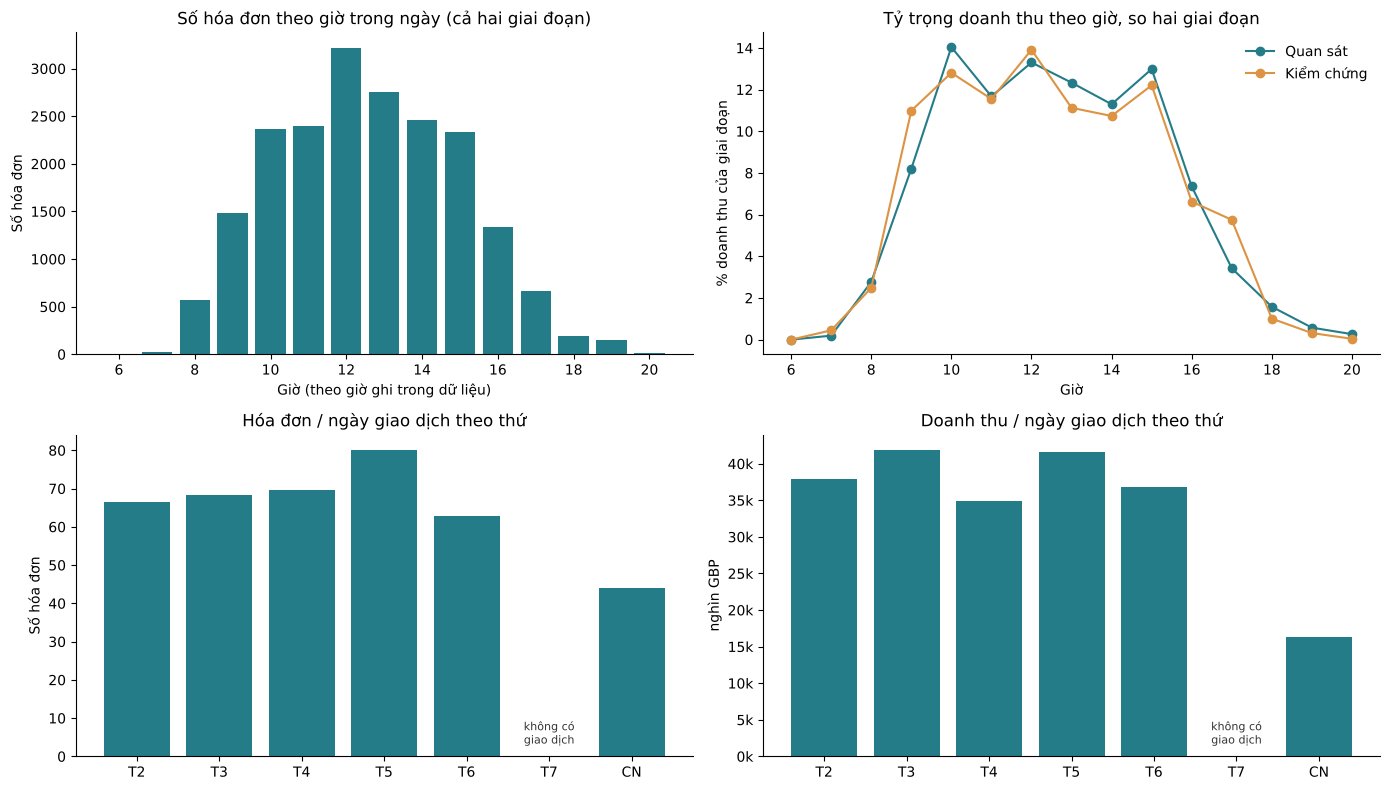

**Nhận xét biểu đồ:** Hóa đơn tập trung vào ban ngày: khung 10h–15h chiếm 77.8% số hóa đơn và 74.4% doanh thu, cao nhất lúc 12h (3,219 hóa đơn), hầu như không có sau 19h. Không có giao dịch thứ Bảy; thứ 5 đông nhất (80 hóa đơn/ngày) còn Chủ nhật chỉ 44 hóa đơn và £16,277/ngày (thứ 3 cao nhất với £41,897/ngày). Tỷ trọng doanh thu theo giờ của hai giai đoạn lệch nhau tối đa 2.8 điểm phần trăm, nên nhịp trong ngày và trong tuần ổn định qua cutoff và không phải nguyên nhân làm hai giai đoạn khác nhau.

In [5]:
inv = et.invoice_table(sales)
hourly = et.hour_profile(inv)
weekday = et.weekday_profile(inv, sales)
display(hourly)
display(weekday)
hourly.to_csv(TABLES_DIR / 'eda_time_hourly.csv', encoding='utf-8-sig')
weekday.to_csv(TABLES_DIR / 'eda_time_weekday.csv', encoding='utf-8-sig')

assert hourly.invoices.idxmax() == 12
assert weekday.invoices_per_day.idxmax() == 3  # thứ 5

et.plot_hour_dow(hourly, weekday)

core = inv.hour.between(10, 15)
share_gap = (hourly['revenue_pct_obs'] - hourly['revenue_pct_val']).abs()
thu, sun = weekday.loc[3], weekday.loc[6]
top_rev_day = weekday.revenue_per_day.idxmax()
display(Markdown(
    f"**Nhận xét biểu đồ:** Hóa đơn tập trung vào ban ngày: khung 10h–15h chiếm {core.mean() * 100:.1f}% số hóa đơn và {inv.loc[core, 'revenue'].sum() / inv.revenue.sum() * 100:.1f}% doanh thu, "
    f"cao nhất lúc 12h ({int(hourly.invoices.max()):,} hóa đơn), hầu như không có sau 19h. "
    f"Không có giao dịch thứ Bảy; thứ 5 đông nhất ({thu.invoices_per_day:.0f} hóa đơn/ngày) còn Chủ nhật chỉ {sun.invoices_per_day:.0f} hóa đơn và £{sun.revenue_per_day:,.0f}/ngày "
    f"(thứ {top_rev_day + 2} cao nhất với £{weekday.revenue_per_day.max():,.0f}/ngày). "
    f"Tỷ trọng doanh thu theo giờ của hai giai đoạn lệch nhau tối đa {share_gap.max():.1f} điểm phần trăm, "
    "nên nhịp trong ngày và trong tuần ổn định qua cutoff và không phải nguyên nhân làm hai giai đoạn khác nhau."
))

## 5. Tháng 12/2011 chỉ có đến 09/12 và các hóa đơn lớn bị hủy

Tháng 12/2011 có dữ liệu đến một thời điểm cụ thể (không phải hết ngày). Vì không có năm trước để so cả tháng, cách so công bằng duy nhất là **cùng 9 ngày đầu** của 12/2010 và 12/2011. Bảng đầu liệt kê 5 hóa đơn lớn nhất toàn dữ liệu và hóa đơn hủy khớp với chúng (cùng khách, mã hàng, số lượng đối nhau, giá trị bằng nhau, xảy ra sau đó), vì một hóa đơn rất lớn sẽ làm lệch cả tuần/tháng chứa nó.

,InvoiceNo,InvoiceDate,CustomerID,lines,revenue,cancel_invoice,cancel_minutes_later,cancelled_value
0,581483,2011-12-09 09:15:00,16446,1,"168,469.6",C581484,12.0,"168,469.6"
1,541431,2011-01-18 10:01:00,12346,1,"77,183.6",C541433,16.0,"77,183.6"
2,574941,2011-11-07 17:42:00,<NA>,101,"52,940.9",NaN,NaN,0.0
3,576365,2011-11-14 17:55:00,<NA>,99,"50,653.9",NaN,NaN,0.0
4,556444,2011-06-10 15:28:00,15098,1,"38,970.0",NaN,NaN,0.0


,trading_days,invoices,customers,revenue
case,,,,
1–9/12/2010,8,834,573,"438,852.7"
1–9/12/2011,8,819,615,"638,792.7"
"1–9/12/2011, bỏ hóa đơn lớn nhất (581483)",8,818,614,"470,323.1"


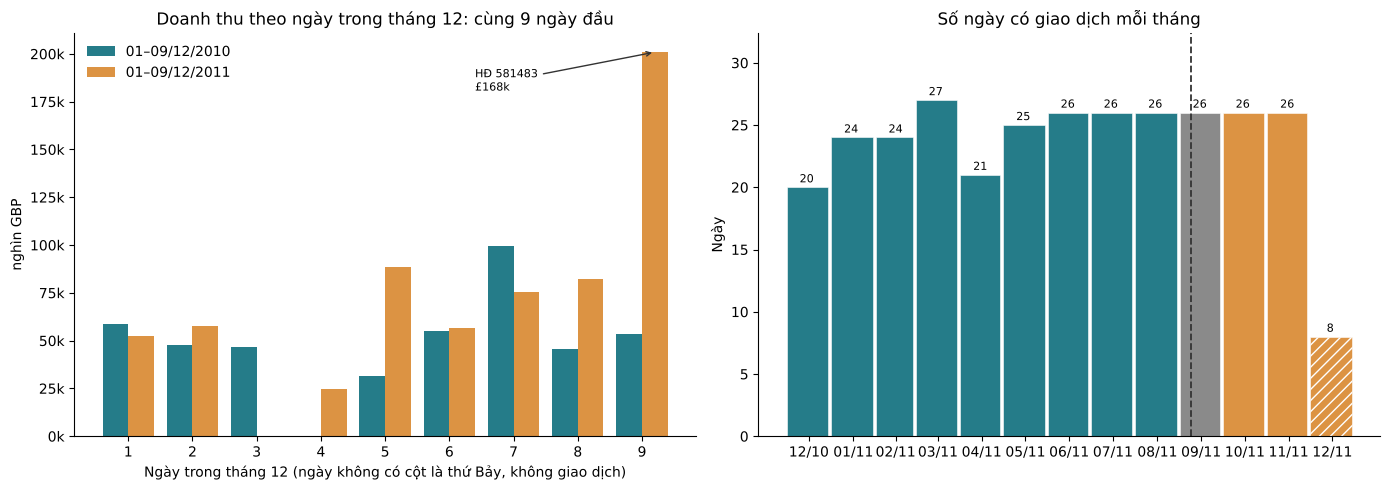

**Nhận xét biểu đồ:** Dữ liệu dừng lúc 12:50 ngày 09/12/2011, nên 12/2011 chỉ có 8 ngày giao dịch và tổng tháng không so được với các tháng khác. Cùng 9 ngày đầu tháng, 2011 đạt £638,793 so với £438,853 của 2010 (+46%) dù số hóa đơn gần như bằng nhau (819 so với 834). Phần lớn chênh lệch (84%) đến từ hóa đơn 581483 trị giá £168,470 lúc 09:15 ngày 09/12, bị hóa đơn hủy C581484 xóa sau 12 phút; bỏ hóa đơn này, mức tăng chỉ còn +7% (£470,323).

*Ghi chú:* ca tương tự nằm trong giai đoạn quan sát: hóa đơn 541431 (khách 12346) £77,184 ngày 18/01/2011 bị hủy bởi C541433 sau 16 phút, chiếm 11% doanh thu gộp 01/2011. Doanh thu ở notebook này là doanh thu **gộp** (chưa trừ hủy), nên cần nhớ khi đọc các đỉnh; ở các bước tính Monetary và chi tiêu kiểm chứng, hai đơn kiểu này nên được xử lý có chủ đích (ví dụ trừ hủy hoặc báo cáo độ nhạy).

In [6]:
top_inv = et.largest_invoices(sales, raw, n=5)
display(top_inv)
daily_dec, dec_table, top_invoice = et.december_like_for_like(sales, days=9)
display(dec_table)
top_inv.to_csv(TABLES_DIR / 'eda_time_largest_invoices.csv', index=False, encoding='utf-8-sig')
dec_table.to_csv(TABLES_DIR / 'eda_time_december.csv', encoding='utf-8-sig')

first, second = top_inv.iloc[0], top_inv.iloc[1]
assert top_invoice == first.InvoiceNo and pd.notna(first.cancel_invoice) and pd.notna(second.cancel_invoice)
assert first.InvoiceDate.strftime('%Y-%m-%d') == '2011-12-09' and second.InvoiceDate.strftime('%Y-%m') == '2011-01'

et.plot_dec_compare(daily_dec, monthly, float(first.revenue), top_invoice)

last_ts = raw.InvoiceDate.max()
r10, r11, r11_rest = dec_table.iloc[0], dec_table.iloc[1], dec_table.iloc[2]
jan = monthly.set_index('period').loc['2011-01']
display(Markdown(
    f"**Nhận xét biểu đồ:** Dữ liệu dừng lúc {last_ts:%H:%M} ngày {last_ts:%d/%m/%Y}, nên 12/2011 chỉ có {int(r11.trading_days)} ngày giao dịch và tổng tháng không so được với các tháng khác. "
    f"Cùng 9 ngày đầu tháng, 2011 đạt £{r11.revenue:,.0f} so với £{r10.revenue:,.0f} của 2010 (+{(r11.revenue / r10.revenue - 1) * 100:.0f}%) "
    f"dù số hóa đơn gần như bằng nhau ({int(r11.invoices)} so với {int(r10.invoices)}). "
    f"Phần lớn chênh lệch ({first.revenue / (r11.revenue - r10.revenue) * 100:.0f}%) đến từ hóa đơn {first.InvoiceNo} trị giá £{first.revenue:,.0f} lúc {first.InvoiceDate:%H:%M} ngày 09/12, "
    f"bị hóa đơn hủy {first.cancel_invoice} xóa sau {first.cancel_minutes_later:.0f} phút; bỏ hóa đơn này, mức tăng chỉ còn +{(r11_rest.revenue / r10.revenue - 1) * 100:.0f}% (£{r11_rest.revenue:,.0f})."
))
display(Markdown(
    f"*Ghi chú:* ca tương tự nằm trong giai đoạn quan sát: hóa đơn {second.InvoiceNo} (khách {second.CustomerID}) £{second.revenue:,.0f} ngày {second.InvoiceDate:%d/%m/%Y} "
    f"bị hủy bởi {second.cancel_invoice} sau {second.cancel_minutes_later:.0f} phút, chiếm {second.revenue / jan.revenue * 100:.0f}% doanh thu gộp 01/2011. "
    "Doanh thu ở notebook này là doanh thu **gộp** (chưa trừ hủy), nên cần nhớ khi đọc các đỉnh; ở các bước tính Monetary và chi tiêu kiểm chứng, hai đơn kiểu này nên được xử lý có chủ đích (ví dụ trừ hủy hoặc báo cáo độ nhạy)."
))

## 6. CUTOFF và độ tương đương của hai giai đoạn

Giai đoạn quan sát là giao dịch trước `2011-09-09`, giai đoạn kiểm chứng là từ `2011-09-09` đến hết dữ liệu. Bảng dưới đếm cả **dòng gốc (chưa lọc)** theo đúng định nghĩa chia theo thời gian của đề bài, **dòng bán hợp lệ**, **hóa đơn** và **khách**, rồi chuẩn hóa theo ngày giao dịch vì hai giai đoạn dài ngắn rất khác nhau. Phần giao nhau của khách chỉ là số đếm mô tả, không dùng để chọn mô hình.

,Quan sát,Kiểm chứng,Kiểm chứng / Quan sát
Ngày lịch trong giai đoạn,282,92,0.33
Ngày có giao dịch bán,226,79,0.35
Dòng gốc (chưa lọc),"332,447","209,462",0.63
Dòng bán hợp lệ (sau bộ lọc nhẹ),"324,631","205,473",0.63
Hóa đơn bán,"12,955","7,005",0.54
Khách trong dữ liệu gốc (kể cả chỉ có hóa đơn hủy),"3,404","2,927",0.86
Khách có mua (CustomerID không thiếu),"3,362","2,897",0.86
"Doanh thu gộp (GBP, chưa trừ hủy)","6,528,754","4,137,930",0.63
Doanh thu / ngày giao dịch (GBP),"28,888.29","52,378.87",1.81
Hóa đơn / ngày giao dịch,57.32,88.67,1.55


{'obs_customers': 3362, 'val_customers': 2897, 'in_both': 1921, 'only_val': 976, 'only_obs': 1441}

,rev_per_trading_day_gbp
01–08/09/2011 (trước cutoff),"31,989.7"
09–30/09/2011 (sau cutoff),"43,929.6"
03–08/2011 (nền),"28,252.2"


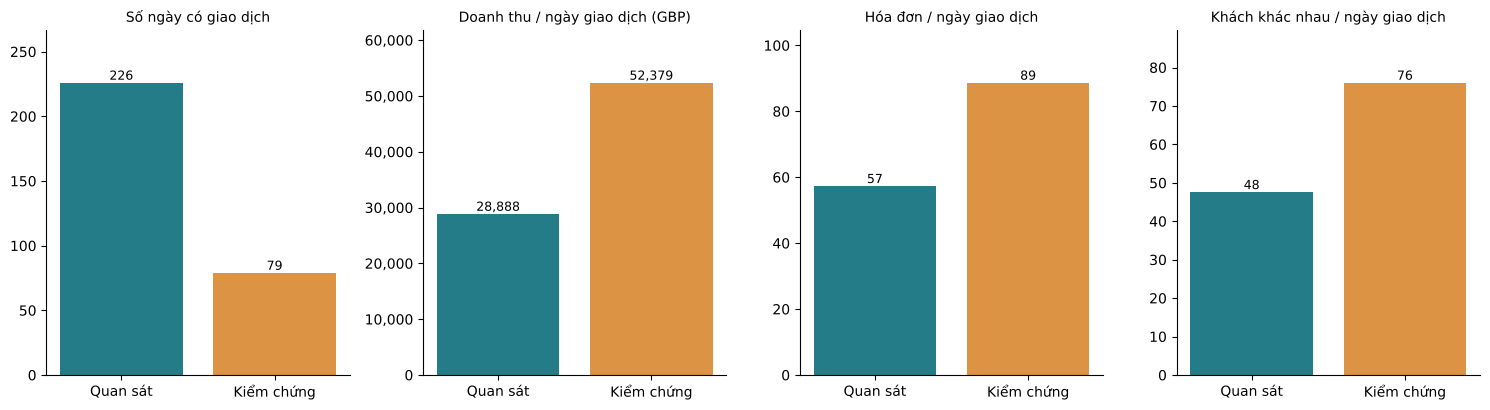

**Nhận xét biểu đồ:** Giai đoạn quan sát có 332,447 dòng gốc (324,631 dòng bán hợp lệ), 12,955 hóa đơn và 3,362 khách trong 226 ngày giao dịch; giai đoạn kiểm chứng có 209,462 dòng gốc (205,473 hợp lệ), 7,005 hóa đơn và 2,897 khách trong 79 ngày. Tính theo ngày giao dịch, giai đoạn kiểm chứng có doanh thu gấp 1.81 lần, hóa đơn gấp 1.55 lần và số khách gấp 1.60 lần giai đoạn quan sát, nên hai giai đoạn **không tương đương** về cường độ mua. Nguyên nhân chủ yếu là mùa vụ: giai đoạn quan sát chứa nền thấp 03–08/2011 (£28,252/ngày giao dịch) cùng đỉnh 12/2010, còn giai đoạn kiểm chứng chứa trọn đợt tăng cuối năm, ngay trong tháng 9 doanh thu/ngày đã tăng từ £31,990 (trước 09/09) lên £43,930 (sau 09/09).

In [7]:
periods = et.compare_periods(raw, sales)
overlap = et.customer_overlap(sales)
assert periods.loc['Dòng gốc (chưa lọc)', et.OBS] == (raw.InvoiceDate < cut).sum()
assert periods.loc['Dòng gốc (chưa lọc)', et.VAL] == (raw.InvoiceDate >= cut).sum()
display(et.format_periods(periods))
display(overlap)
periods.to_csv(TABLES_DIR / 'eda_time_periods.csv', encoding='utf-8-sig')

sep_pre = et.window_rev_per_day(sales, '2011-09-01', '2011-09-09')
sep_post = et.window_rev_per_day(sales, '2011-09-09', '2011-10-01')
base_rpd = et.window_rev_per_day(sales, '2011-03-01', '2011-09-01')
display(pd.DataFrame({'rev_per_trading_day_gbp': {
    '01–08/09/2011 (trước cutoff)': sep_pre, '09–30/09/2011 (sau cutoff)': sep_post, '03–08/2011 (nền)': base_rpd}}))

et.plot_periods(periods)

P = periods
o, v = et.OBS, et.VAL
display(Markdown(
    f"**Nhận xét biểu đồ:** Giai đoạn quan sát có {P.loc['Dòng gốc (chưa lọc)', o]:,.0f} dòng gốc ({P.loc['Dòng bán hợp lệ (sau bộ lọc nhẹ)', o]:,.0f} dòng bán hợp lệ), "
    f"{P.loc['Hóa đơn bán', o]:,.0f} hóa đơn và {P.loc['Khách có mua (CustomerID không thiếu)', o]:,.0f} khách trong {P.loc['Ngày có giao dịch bán', o]:.0f} ngày giao dịch; "
    f"giai đoạn kiểm chứng có {P.loc['Dòng gốc (chưa lọc)', v]:,.0f} dòng gốc ({P.loc['Dòng bán hợp lệ (sau bộ lọc nhẹ)', v]:,.0f} hợp lệ), "
    f"{P.loc['Hóa đơn bán', v]:,.0f} hóa đơn và {P.loc['Khách có mua (CustomerID không thiếu)', v]:,.0f} khách trong {P.loc['Ngày có giao dịch bán', v]:.0f} ngày. "
    f"Tính theo ngày giao dịch, giai đoạn kiểm chứng có doanh thu gấp {P.loc['Doanh thu / ngày giao dịch (GBP)', 'Kiểm chứng / Quan sát']:.2f} lần, "
    f"hóa đơn gấp {P.loc['Hóa đơn / ngày giao dịch', 'Kiểm chứng / Quan sát']:.2f} lần và số khách gấp {P.loc['Khách khác nhau / ngày giao dịch (TB)', 'Kiểm chứng / Quan sát']:.2f} lần giai đoạn quan sát, "
    "nên hai giai đoạn **không tương đương** về cường độ mua. "
    f"Nguyên nhân chủ yếu là mùa vụ: giai đoạn quan sát chứa nền thấp 03–08/2011 (£{base_rpd:,.0f}/ngày giao dịch) cùng đỉnh 12/2010, "
    f"còn giai đoạn kiểm chứng chứa trọn đợt tăng cuối năm, ngay trong tháng 9 doanh thu/ngày đã tăng từ £{sep_pre:,.0f} (trước 09/09) lên £{sep_post:,.0f} (sau 09/09)."
))

## 7. Kết luận và hạn chế cần ghi vào báo cáo

In [8]:
n_obs, n_val = overlap['obs_customers'], overlap['val_customers']
display(Markdown(f'''
**Hai giai đoạn không tương đương về mùa vụ.** Giai đoạn quan sát ({P.loc['Ngày có giao dịch bán', o]:.0f} ngày giao dịch) chủ yếu là nền thấp 01–08/2011 cộng đỉnh 12/2010; giai đoạn kiểm chứng ({P.loc['Ngày có giao dịch bán', v]:.0f} ngày) trùng đợt mua cuối năm. Hạn chế cần ghi vào báo cáo:

1. **Cường độ mua ở giai đoạn kiểm chứng cao hơn do mùa vụ.** Doanh thu/ngày giao dịch gấp {P.loc['Doanh thu / ngày giao dịch (GBP)', 'Kiểm chứng / Quan sát']:.2f} lần. Với RQ3, mức chi tiêu và tỷ lệ quay lại tuyệt đối có thể bị thổi phồng so với một giai đoạn bình thường; kết luận nên dựa vào **so sánh giữa các cụm/mô hình trên cùng một cửa sổ kiểm chứng**, không diễn giải mức tuyệt đối như hành vi quanh năm.
2. **Chỉ có một năm dữ liệu.** Không có năm trước để ước lượng và hiệu chỉnh mùa vụ; phép so sánh cùng kỳ duy nhất khả thi là 01–09/12 của 2010 và 2011 (mục 5).
3. **Giai đoạn kiểm chứng kết thúc ở đầu tháng 12 và giữa ngày** (09/12/2011 lúc {last_ts:%H:%M}), chỉ {P.loc['Ngày lịch trong giai đoạn', v]:.0f} ngày lịch; không dùng tổng tháng 12/2011.
4. **Hóa đơn lớn bị hủy sau vài phút** ({first.InvoiceNo}: £{first.revenue:,.0f}; {second.InvoiceNo}: £{second.revenue:,.0f}) làm doanh thu gộp cao ảo; cần quyết định cách trừ hủy khi tính Monetary và chi tiêu kiểm chứng.
5. **Thiếu `CustomerID`:** {P.loc['Doanh thu thuộc dòng thiếu CustomerID (%)', o]:.1f}% doanh thu giai đoạn quan sát và {P.loc['Doanh thu thuộc dòng thiếu CustomerID (%)', v]:.1f}% giai đoạn kiểm chứng không gán được cho khách; tỷ trọng cao ở 12/2010–01/2011 khiến khách đầu kỳ bị đếm thấp tương đối.
6. **Khách mới ở giai đoạn kiểm chứng:** {overlap['only_val']:,} khách ({overlap['only_val'] / n_val * 100:.1f}% khách kiểm chứng) chưa có lịch sử ở giai đoạn quan sát nên không có RFM; ngược lại {overlap['in_both']:,}/{n_obs:,} khách quan sát ({overlap['in_both'] / n_obs * 100:.1f}%) có mua lại ở giai đoạn kiểm chứng. RQ3 chỉ đánh giá được nhóm khách đã có trong giai đoạn quan sát.
7. **Khoảng không giao dịch cuối năm** ({gaps.start[0]:%d/%m/%Y}–{gaps.end[0]:%d/%m/%Y}) và việc không có thứ Bảy là đặc điểm lịch của cửa hàng, có thể làm `AvgInterPurchaseDays` của khách mua quanh kỳ nghỉ dài hơn thực tế; cần ghi chú khi diễn giải đặc trưng này.

Nhịp trong ngày/tuần ổn định giữa hai giai đoạn (mục 4), nên hạn chế chính nằm ở mùa vụ và tháng cuối, không nằm ở giờ hay thứ giao dịch. Các phát hiện này **không thay đổi thiết kế thực nghiệm** (cutoff, đặc trưng, scaler fit ở giai đoạn quan sát); chúng chỉ là điều kiện để diễn giải RQ3.
'''))


**Hai giai đoạn không tương đương về mùa vụ.** Giai đoạn quan sát (226 ngày giao dịch) chủ yếu là nền thấp 01–08/2011 cộng đỉnh 12/2010; giai đoạn kiểm chứng (79 ngày) trùng đợt mua cuối năm. Hạn chế cần ghi vào báo cáo:

1. **Cường độ mua ở giai đoạn kiểm chứng cao hơn do mùa vụ.** Doanh thu/ngày giao dịch gấp 1.81 lần. Với RQ3, mức chi tiêu và tỷ lệ quay lại tuyệt đối có thể bị thổi phồng so với một giai đoạn bình thường; kết luận nên dựa vào **so sánh giữa các cụm/mô hình trên cùng một cửa sổ kiểm chứng**, không diễn giải mức tuyệt đối như hành vi quanh năm.
2. **Chỉ có một năm dữ liệu.** Không có năm trước để ước lượng và hiệu chỉnh mùa vụ; phép so sánh cùng kỳ duy nhất khả thi là 01–09/12 của 2010 và 2011 (mục 5).
3. **Giai đoạn kiểm chứng kết thúc ở đầu tháng 12 và giữa ngày** (09/12/2011 lúc 12:50), chỉ 92 ngày lịch; không dùng tổng tháng 12/2011.
4. **Hóa đơn lớn bị hủy sau vài phút** (581483: £168,470; 541431: £77,184) làm doanh thu gộp cao ảo; cần quyết định cách trừ hủy khi tính Monetary và chi tiêu kiểm chứng.
5. **Thiếu `CustomerID`:** 16.8% doanh thu giai đoạn quan sát và 15.9% giai đoạn kiểm chứng không gán được cho khách; tỷ trọng cao ở 12/2010–01/2011 khiến khách đầu kỳ bị đếm thấp tương đối.
6. **Khách mới ở giai đoạn kiểm chứng:** 976 khách (33.7% khách kiểm chứng) chưa có lịch sử ở giai đoạn quan sát nên không có RFM; ngược lại 1,921/3,362 khách quan sát (57.1%) có mua lại ở giai đoạn kiểm chứng. RQ3 chỉ đánh giá được nhóm khách đã có trong giai đoạn quan sát.
7. **Khoảng không giao dịch cuối năm** (24/12/2010–03/01/2011) và việc không có thứ Bảy là đặc điểm lịch của cửa hàng, có thể làm `AvgInterPurchaseDays` của khách mua quanh kỳ nghỉ dài hơn thực tế; cần ghi chú khi diễn giải đặc trưng này.

Nhịp trong ngày/tuần ổn định giữa hai giai đoạn (mục 4), nên hạn chế chính nằm ở mùa vụ và tháng cuối, không nằm ở giờ hay thứ giao dịch. Các phát hiện này **không thay đổi thiết kế thực nghiệm** (cutoff, đặc trưng, scaler fit ở giai đoạn quan sát); chúng chỉ là điều kiện để diễn giải RQ3.


In [9]:
summary = {
    'cutoff': CUTOFF, 'rows_raw': len(raw), 'rows_sales': len(sales),
    'date_min': str(raw.InvoiceDate.min()), 'date_max': str(raw.InvoiceDate.max()),
    'periods': {k: {m_: (float(P.loc[m_, k])) for m_ in P.index} for k in (o, v)},
    'customer_overlap': overlap,
    'largest_invoice_cancelled': {
        'invoice': first.InvoiceNo, 'revenue': float(first.revenue), 'cancel_invoice': first.cancel_invoice,
        'minutes_later': float(first.cancel_minutes_later),
    },
    'versions': versions, 'python': platform.python_version(),
}
(TABLES_DIR / 'eda_time_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(
    '**Tái lập:** dùng kernel có các thư viện trong `requirements.txt`, chọn Kernel → Restart & Run All. '
    'Năm hình được lưu ở `reports/figures/eda_time_*.png`, các bảng ở `reports/tables/eda_time_*`. '
    'Notebook đọc lại file Excel gốc mỗi lần chạy và không dùng kết quả của lần chạy trước.'
))
display(sorted(p.name for p in FIGURES_DIR.glob('eda_time_*.png')))

**Tái lập:** dùng kernel có các thư viện trong `requirements.txt`, chọn Kernel → Restart & Run All. Năm hình được lưu ở `reports/figures/eda_time_*.png`, các bảng ở `reports/tables/eda_time_*`. Notebook đọc lại file Excel gốc mỗi lần chạy và không dùng kết quả của lần chạy trước.

['eda_time_dec_compare.png',
 'eda_time_hour_dow.png',
 'eda_time_monthly.png',
 'eda_time_periods.png',
 'eda_time_weekly.png']